# Лабораторная работа №6. Matching, DLT, RANSAC и гомография

Условие — в [методичке](CSE5382_15_лабораторных_работ_математические_методы_in_CV.md), раздел «Лабораторная работа №6».

**Данные.** `data/box.png` (коробка крупным планом) и `data/box_in_scene.png` (та же коробка на столе среди других предметов) — стандартная пара из примеров OpenCV.

> **Что нужно заменить перед сдачей.** Шаг 1 задания требует *сделать две собственные фотографии* одной сцены. Здесь взята готовая пара, чтобы ноутбук запускался без камеры. Код от изображений не зависит: достаточно поменять два пути в ячейке параметров и переписать вывод по новым числам.

## 1. О чём эта работа

### Знакомый пример

Панорама в телефоне: вы ведёте камерой, а телефон склеивает кадры в одну длинную картинку. Для этого ему нужно понять, как один кадр расположен относительно другого. Или дополненная реальность: приложение узнаёт обложку книги на столе и рисует поверх неё видео, повторяя наклон обложки.

### Основная идея

Три шага.

1. **Найти пары одинаковых точек** на двух снимках. У каждой особой точки (лабораторная 5) есть «паспорт» — дескриптор, набор чисел, описывающий её окрестность. Точки с похожими паспортами считаем парой.
2. **Отсеять ошибки.** Похожие паспорта бывают у разных точек (одинаковые буквы, окна, плитка). Часть пар неверна.
3. **Найти преобразование**, которое переводит точки первого снимка в точки второго. Для плоского объекта (обложка, стена, пол) это **гомография**.

### Понятия

- **Дескриптор** — вектор чисел, описывающий окрестность точки (у SIFT — 128 чисел). **Расстояние между дескрипторами** — мера непохожести.
- **Match** — пара «точка на A ↔ точка на B» с самым близким дескриптором.
- **Ratio test** (тест Лоу). Для точки на A находим двух ближайших кандидатов на B: расстояния $d_1\le d_2$. Если лучший кандидат намного лучше второго ($d_1/d_2<T$), пара надёжна. Если они почти одинаковы — точка неоднозначна, пару выбрасываем.
- **Однородные координаты** — приём: точку $(x,y)$ записывают тремя числами $(x,y,1)$, причём $(x,y,1)$ и $(2x,2y,2)$ считаются одной точкой. Чтобы вернуться к обычным координатам, первые два числа делят на третье. Приём нужен, чтобы перспективу («дальнее выглядит меньше» — это деление на расстояние) записать одним матричным умножением.
- **Гомография** $H$ — матрица 3×3, переводящая точки одной плоскости в точки другой: $s\,x'=Hx$. Множитель $s$ — то самое «третье число», на которое потом делят. У $H$ 9 чисел, но общий масштаб не важен, поэтому независимых параметров 8. Каждая пара точек даёт 2 уравнения — значит, нужно минимум **4 пары**.
- **Inlier / outlier** — пара, согласующаяся с найденным преобразованием / не согласующаяся (ошибка).
- **DLT** (Direct Linear Transform) — способ найти $H$ из пар точек, решая линейную систему.
- **RANSAC** — способ найти $H$, когда среди пар много ошибок: много раз берём случайные 4 пары, считаем по ним $H$, смотрим, сколько остальных пар с ней согласны; оставляем лучший вариант.
- **Reprojection error** — расстояние в пикселях между тем, куда $H$ отправила точку, и тем, где её пара на самом деле.

### Формулы

$$s\,x'=Hx,\qquad \text{ratio}=\frac{d_1}{d_2}$$

Число итераций RANSAC:

$$N=\frac{\ln(1-p)}{\ln(1-w^s)}$$

$w$ — доля inliers среди пар, $s$ — размер выборки (4 для гомографии), $p$ — с какой вероятностью мы хотим хотя бы раз вытащить выборку только из inliers.

Ошибка репроекции: $e_i=\|x_i'-\pi(Hx_i)\|_2$, где $\pi$ — деление на третью координату.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "image.cmap": "gray"})

IMAGE_A = "data/box.png"
IMAGE_B = "data/box_in_scene.png"
RATIO_T = 0.75
RANSAC_THR = 3.0
cv2.setRNGSeed(0)
rng = np.random.default_rng(0)

## 2. Вопрос 1 — ratio test

> Для d1=42, d2=68 и T=0.75 решите, проходит ли match. Повторите для d1=55, d2=65.

- Первая пара: $42/68\approx0.618<0.75$ — **принимается**. Лучший кандидат на 38 % ближе второго: он выделяется.
- Вторая пара: $55/65\approx0.846>0.75$ — **отклоняется**. Лучший кандидат лишь на 15 % ближе второго: похожих мест на втором снимке как минимум два, и какое из них правильное — неизвестно.

**На что обратить внимание.** Тест не смотрит на абсолютную величину $d_1$. Если бы у второй пары было $d_1=20$, $d_2=22$ — очень близкие дескрипторы, — она всё равно была бы отклонена (0.909). Малое расстояние означает «очень похоже», но не означает «однозначно».

In [2]:
for d1, d2 in [(42, 68), (55, 65), (20, 22)]:
    r = d1 / d2
    print(f"d1={d1}, d2={d2}: ratio = {r:.3f} → {'принять' if r < RATIO_T else 'отклонить'}")

d1=42, d2=68: ratio = 0.618 → принять
d1=55, d2=65: ratio = 0.846 → отклонить
d1=20, d2=22: ratio = 0.909 → отклонить


**Итог вопроса 1:** первый match проходит (0.618), второй — нет (0.846).

## 3. Вопрос 2 — число итераций RANSAC и строки DLT

> Для p=0.995, w=0.55, s=4 вычислите число RANSAC iterations. Затем выпишите две строки DLT-матрицы для (2,3)→(5,7) и объясните роль SVD.

### Число итераций

**Вывод формулы.** Одна пара — inlier с вероятностью $w$. Все $s=4$ пары в выборке — inliers с вероятностью $w^4$. Выборка «испорчена» с вероятностью $1-w^4$. Все $N$ выборок испорчены с вероятностью $(1-w^4)^N$. Требуем, чтобы это было не больше $1-p$, и решаем относительно $N$ логарифмированием.

**Числа.** $w^4=0.55^4=0.0915$ — чистой оказывается только каждая одиннадцатая выборка. $1-w^4=0.9085$.

$$N=\frac{\ln(1-0.995)}{\ln(0.9085)}=\frac{\ln 0.005}{\ln 0.9085}=\frac{-5.2983}{-0.09597}\approx55.2\ \to\ 56$$

Округляем вверх: итераций должно быть не меньше.

(В методичке записано ≈55.15; прямой расчёт даёт ≈55.21. На ответ 56 это не влияет.)

### Строки DLT

Запишем $H$ по строкам: $h_1^T,h_2^T,h_3^T$. Из $s\,x'=Hx$ после деления на третью координату:

$$x'=\frac{h_1^Tx}{h_3^Tx},\qquad y'=\frac{h_2^Tx}{h_3^Tx}$$

Домножаем на знаменатель и переносим всё влево — получаем два уравнения, **линейных** относительно девяти неизвестных $h=(h_{11},\dots,h_{33})$:

$$[-x,\,-y,\,-1,\ 0,0,0,\ x'x,\,x'y,\,x']\cdot h=0$$
$$[0,0,0,\ -x,\,-y,\,-1,\ y'x,\,y'y,\,y']\cdot h=0$$

Подставляем $(x,y)=(2,3)$, $(x',y')=(5,7)$:

- строка 1: $[-2,-3,-1,\ 0,0,0,\ 5\cdot2,\ 5\cdot3,\ 5]=[-2,-3,-1,0,0,0,10,15,5]$
- строка 2: $[0,0,0,\ -2,-3,-1,\ 7\cdot2,\ 7\cdot3,\ 7]=[0,0,0,-2,-3,-1,14,21,7]$

Четыре пары дают матрицу $A$ размера 8×9, $n$ пар — $2n\times9$.

### Роль SVD

Нужно решить $Ah=0$. Решение $h=0$ бесполезно, поэтому фиксируем масштаб: $\|h\|=1$. Если пар больше четырёх и в координатах есть шум, точного решения нет, и ищут $h$, минимизирующий $\|Ah\|$.

**SVD** раскладывает любую матрицу: $A=U\Sigma V^T$, где столбцы $V$ — взаимно перпендикулярные единичные направления во входном пространстве, а сингулярные числа $\sigma_i$ на диагонали $\Sigma$ показывают, во сколько раз $A$ растягивает каждое из них. Направление, которое $A$ растягивает меньше всего, — последний столбец $V$ (для наименьшего $\sigma$). Это и есть искомый $h$: единичный вектор, для которого $\|Ah\|$ минимально. При точных данных $\sigma_{min}=0$ и $Ah=0$ выполняется точно.

In [3]:
p, w, s = 0.995, 0.55, 4
N_exact = np.log(1 - p) / np.log(1 - w ** s)
print(f"w^s = {w ** s:.6f}, 1 − w^s = {1 - w ** s:.6f}")
print(f"N = ln({1 - p:.3f}) / ln({1 - w ** s:.6f}) = {np.log(1 - p):.4f} / {np.log(1 - w ** s):.5f} = {N_exact:.3f} → {int(np.ceil(N_exact))}")
print("как N зависит от доли inliers (p=0.995, s=4):")
for ww in (0.9, 0.7, 0.55, 0.4, 0.25, 0.1):
    print(f"  w = {ww:4.2f}: N = {int(np.ceil(np.log(1 - p) / np.log(1 - ww ** s))):6d}")

def dlt_rows(x, y, xp, yp):
    return np.array([[-x, -y, -1, 0, 0, 0, xp * x, xp * y, xp],
                     [0, 0, 0, -x, -y, -1, yp * x, yp * y, yp]], dtype=float)

print("\nстроки DLT для (2,3)→(5,7):\n", dlt_rows(2, 3, 5, 7))

w^s = 0.091506, 1 − w^s = 0.908494
N = ln(0.005) / ln(0.908494) = -5.2983 / -0.09597 = 55.210 → 56
как N зависит от доли inliers (p=0.995, s=4):
  w = 0.90: N =      5
  w = 0.70: N =     20
  w = 0.55: N =     56
  w = 0.40: N =    205
  w = 0.25: N =   1354
  w = 0.10: N =  52981

строки DLT для (2,3)→(5,7):
 [[-2. -3. -1.  0.  0.  0. 10. 15.  5.]
 [ 0.  0.  0. -2. -3. -1. 14. 21.  7.]]


**Итог вопроса 2:** $N=56$; строки `[−2,−3,−1,0,0,0,10,15,5]` и `[0,0,0,−2,−3,−1,14,21,7]`.

Таблица показывает, почему доля inliers так важна: при $w=0.9$ хватает 5 итераций, при $w=0.25$ нужно 1354, при $w=0.1$ — около 53 тысяч.

### Собственный DLT и проверка

Реализуем DLT целиком и проверим на точках с известной гомографией. Перед составлением $A$ точки нормируются (сдвиг центра в ноль, масштаб до среднего расстояния $\sqrt2$): иначе в одной матрице оказываются числа порядка 1 и порядка $10^5$ (произведения пиксельных координат), и решение становится численно неустойчивым.

In [4]:
def normalize_points(pts):
    c = pts.mean(axis=0)
    scale = np.sqrt(2) / np.linalg.norm(pts - c, axis=1).mean()
    T = np.array([[scale, 0, -scale * c[0]], [0, scale, -scale * c[1]], [0, 0, 1]])
    return (pts - c) * scale, T

def dlt_homography(src, dst):
    """H из n ≥ 4 пар: правый сингулярный вектор A для наименьшего сингулярного числа."""
    s_n, Ts = normalize_points(np.asarray(src, float))
    d_n, Td = normalize_points(np.asarray(dst, float))
    A = np.vstack([dlt_rows(x, y, xp, yp) for (x, y), (xp, yp) in zip(s_n, d_n)])
    _, S, Vt = np.linalg.svd(A)
    Hn = Vt[-1].reshape(3, 3)
    H = np.linalg.inv(Td) @ Hn @ Ts
    return H / H[2, 2], S

def project_points(H, pts):
    pts = np.asarray(pts, dtype=float)
    pts_h = np.c_[pts, np.ones(len(pts))]       # (x, y) → (x, y, 1)
    q = (H @ pts_h.T).T
    return q[:, :2] / q[:, 2:3]                 # деление на третью координату

H_true = np.array([[0.9, -0.2, 40.0], [0.15, 1.1, -10.0], [2e-4, -1e-4, 1.0]])
src_t = rng.uniform(0, 400, (12, 2))
dst_t = project_points(H_true, src_t)
H_est, S = dlt_homography(src_t, dst_t)
print("max |H_dlt − H_true| =", np.abs(H_est - H_true).max())
print("наименьшее сингулярное число A:", S[-1], "(данные точные → ≈0)")
print("(2,3) → ", project_points(H_true, [[2, 3]])[0])

max |H_dlt − H_true| = 1.1901590823981678e-13
наименьшее сингулярное число A: 6.321688795318383e-16 (данные точные → ≈0)
(2,3) →  [41.1959 -6.3994]


## 4. Задание 3 — код и эксперимент

### Шаги 1–3. Изображения, SIFT, KNN matching с k=2

SIFT выбран потому, что его дескрипторы устойчивы к масштабу и повороту, а коробка на втором снимке меньше и повёрнута. Сопоставление — полным перебором (`BFMatcher`): для каждого дескриптора A ищем **два** ближайших в B — второй нужен для ratio test.

In [5]:
img_a = cv2.imread(IMAGE_A, cv2.IMREAD_GRAYSCALE)
img_b = cv2.imread(IMAGE_B, cv2.IMREAD_GRAYSCALE)
assert img_a is not None and img_b is not None

sift = cv2.SIFT_create()
kp_a, des_a = sift.detectAndCompute(img_a, None)
kp_b, des_b = sift.detectAndCompute(img_b, None)
print("A:", img_a.shape, "keypoints:", len(kp_a), " B:", img_b.shape, "keypoints:", len(kp_b), " дескриптор:", des_a.shape[1], "чисел")

knn = cv2.BFMatcher(cv2.NORM_L2).knnMatch(des_a, des_b, k=2)
d1 = np.array([m.distance for m, n in knn])
d2 = np.array([n.distance for m, n in knn])
ratios = d1 / d2
print("пар кандидатов:", len(knn))

A: (223, 324) keypoints: 604  B: (384, 512) keypoints: 969  дескриптор: 128 чисел
пар кандидатов: 604


### Шаги 4–5. Собственный ratio test и зависимость числа matches от T

T = 0.55: matches = 54
T = 0.60: matches = 60
T = 0.65: matches = 71
T = 0.70: matches = 73
T = 0.75: matches = 80
T = 0.80: matches = 94
T = 0.85: matches = 126
T = 0.90: matches = 174


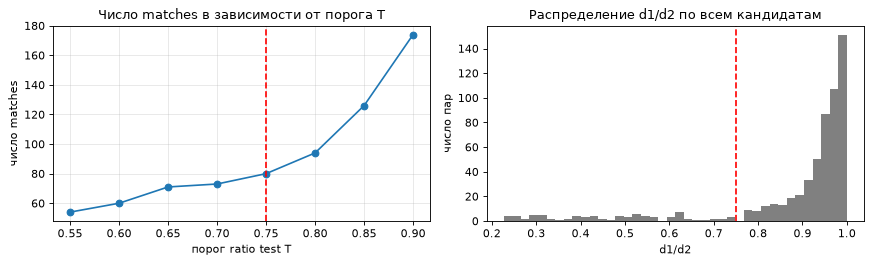

In [6]:
def ratio_test(knn_matches, T):
    return [m for m, n in knn_matches if m.distance < T * n.distance]

Ts = np.arange(0.55, 0.901, 0.05)
counts = [len(ratio_test(knn, T)) for T in Ts]
for T, c in zip(Ts, counts):
    print(f"T = {T:.2f}: matches = {c}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(Ts, counts, "o-"); ax[0].axvline(RATIO_T, color="r", ls="--")
ax[0].set(title="Число matches в зависимости от порога T", xlabel="порог ratio test T", ylabel="число matches"); ax[0].grid(alpha=0.3)
ax[1].hist(ratios, bins=40, color="gray"); ax[1].axvline(RATIO_T, color="r", ls="--")
ax[1].set(title="Распределение d1/d2 по всем кандидатам", xlabel="d1/d2", ylabel="число пар")
plt.tight_layout(); plt.show()

Гистограмма справа объясняет тест: большинство кандидатов имеет ratio около 0.8–1 — лучший и второй сосед почти одинаково далеки, то есть «лучший» выбран случайно. Правильные пары образуют хвост слева.

### Шаги 6–8. Точки, гомография через RANSAC, inlier ratio

In [7]:
good = ratio_test(knn, RATIO_T)
src_pts = np.float32([kp_a[m.queryIdx].pt for m in good])
dst_pts = np.float32([kp_b[m.trainIdx].pt for m in good])

H, inl = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, RANSAC_THR)
inl = inl.ravel().astype(bool)
print("matches после ratio test:", len(good))
print("inliers:", int(inl.sum()), " inlier ratio:", round(inl.mean(), 3))
print("H =\n", H)
w_est = inl.mean()
print(f"при такой доле inliers RANSAC нужно N = {int(np.ceil(np.log(1 - 0.995) / np.log(1 - w_est ** 4)))} итераций (p=0.995)")

matches после ratio test: 80
inliers: 75  inlier ratio: 0.938
H =
 [[  0.4425  -0.1632 118.8446]
 [  0.0012   0.4051 160.9192]
 [ -0.0002  -0.0004   1.    ]]
при такой доле inliers RANSAC нужно N = 4 итераций (p=0.995)


### Шаг 9. Собственный расчёт reprojection error

Проецируем точки A функцией `project_points` (без `cv2.perspectiveTransform`) и измеряем расстояние до их пар на B. Три статистики: среднее, медиана и RMSE — корень из среднего квадрата; RMSE сильнее других реагирует на редкие большие ошибки.

In [8]:
def reprojection_stats(H, src, dst):
    err = np.linalg.norm(project_points(H, src) - dst, axis=1)
    return err, err.mean(), np.median(err), np.sqrt(np.mean(err ** 2))

err_in, mean_in, med_in, rmse_in = reprojection_stats(H, src_pts[inl], dst_pts[inl])
err_all = reprojection_stats(H, src_pts, dst_pts)[0]
print(f"inliers : mean = {mean_in:.3f} px, median = {med_in:.3f} px, RMSE = {rmse_in:.3f} px, max = {err_in.max():.3f} px")
print(f"outliers: median = {np.median(err_all[~inl]):.1f} px, min = {err_all[~inl].min():.1f} px")
print("проверка: cv2.perspectiveTransform даёт то же:", np.allclose(project_points(H, src_pts), cv2.perspectiveTransform(src_pts[None], H)[0], atol=1e-3))

# собственный DLT по inliers против H из OpenCV
H_dlt, _ = dlt_homography(src_pts[inl], dst_pts[inl])
print(f"RMSE собственного DLT по тем же inliers: {reprojection_stats(H_dlt, src_pts[inl], dst_pts[inl])[3]:.3f} px")

inliers : mean = 0.378 px, median = 0.276 px, RMSE = 0.488 px, max = 1.380 px
outliers: median = 119.2 px, min = 16.1 px
проверка: cv2.perspectiveTransform даёт то же: True
RMSE собственного DLT по тем же inliers: 0.488 px


### Шаг 10. Пороги RANSAC 1, 3, 5, 8 px

In [9]:
print(f"{'RANSAC threshold':>17}{'Matches':>9}{'Inliers':>9}{'Inlier ratio':>14}{'RMSE, px':>10}{'сдвиг углов, px':>18}")
h_a, w_a = img_a.shape
corners_a = np.float32([[0, 0], [w_a - 1, 0], [w_a - 1, h_a - 1], [0, h_a - 1]])
ref_corners = project_points(H, corners_a)
thr_table = {}
for thr in (1.0, 3.0, 5.0, 8.0):
    cv2.setRNGSeed(0)
    Ht, it = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC, thr)
    it = it.ravel().astype(bool)
    rmse_t = reprojection_stats(Ht, src_pts[it], dst_pts[it])[3]
    shift = np.linalg.norm(project_points(Ht, corners_a) - ref_corners, axis=1).max()
    thr_table[thr] = (len(good), int(it.sum()), it.mean(), rmse_t)
    print(f"{thr:17.0f}{len(good):9d}{int(it.sum()):9d}{it.mean():14.3f}{rmse_t:10.3f}{shift:18.2f}")

 RANSAC threshold  Matches  Inliers  Inlier ratio  RMSE, px   сдвиг углов, px
                1       80       70         0.875     0.366              0.73
                3       80       75         0.938     0.488              0.00
                5       80       75         0.938     0.488              0.00
                8       80       75         0.938     0.488              0.00


Последний столбец — насколько сместились спроецированные углы коробки относительно варианта с порогом 3 px: показатель того, меняется ли сама гомография.

RMSE здесь считается **только по inliers**, а inlier по определению — пара с ошибкой меньше порога. Поэтому рост RMSE с порогом отчасти заложен в саму процедуру: это не качество $H$, а строгость отбора.

### Шаги 11–12. Проекция углов, inliers и outliers

углы A → B:
 [[118.8446 160.9192]
 [284.1507 175.0853]
 [267.4589 297.941 ]
 [ 89.5935 272.0788]]


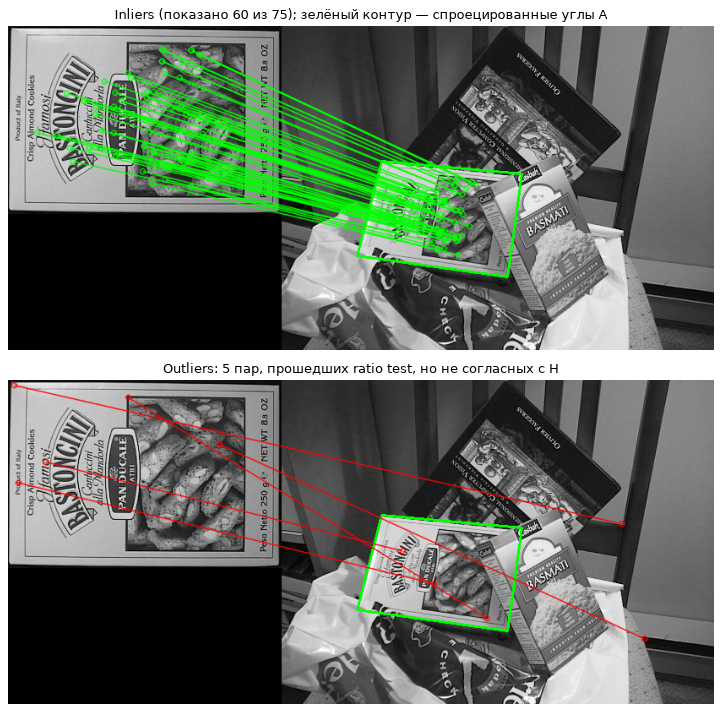

In [10]:
proj = project_points(H, corners_a)
print("углы A → B:\n", proj)

vis_b = cv2.cvtColor(img_b, cv2.COLOR_GRAY2BGR)
cv2.polylines(vis_b, [np.int32(proj)], True, (0, 255, 0), 2)

def draw(matches_idx, color):
    ms = [good[i] for i in matches_idx]
    return cv2.drawMatches(img_a, kp_a, vis_b, kp_b, ms, None, matchColor=color, singlePointColor=None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

idx_in, idx_out = np.nonzero(inl)[0], np.nonzero(~inl)[0]
fig, ax = plt.subplots(2, 1, figsize=(12, 9))
ax[0].imshow(cv2.cvtColor(draw(idx_in[:60], (0, 255, 0)), cv2.COLOR_BGR2RGB)); ax[0].set_title(f"Inliers (показано {min(60, len(idx_in))} из {len(idx_in)}); зелёный контур — спроецированные углы A")
ax[1].imshow(cv2.cvtColor(draw(idx_out, (0, 0, 255)), cv2.COLOR_BGR2RGB)); ax[1].set_title(f"Outliers: {len(idx_out)} пар, прошедших ratio test, но не согласных с H")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Линии inliers идут согласованным «веером» — все точки коробки переходят в коробку. Линии outliers пересекаются и ведут в посторонние предметы.

## 5. Неудачный случай: гомография без RANSAC

Что будет, если поверить всем парам и решить задачу методом наименьших квадратов (DLT по всем matches, в OpenCV — `method=0`)? Сделаем это при мягком пороге ratio test $T=0.9$, когда outliers заведомо много.

T=0.90: matches = 174, из них inliers по RANSAC = 86 (49.4%)
  DLT по всем парам (свой)      : медианная ошибка на верных парах =   264.35 px, сдвиг углов =   1038.3 px
  cv2.findHomography, method=0  : медианная ошибка на верных парах =    40.76 px, сдвиг углов =    139.2 px
  RANSAC                        : медианная ошибка на верных парах =     0.32 px, сдвиг углов =      0.4 px


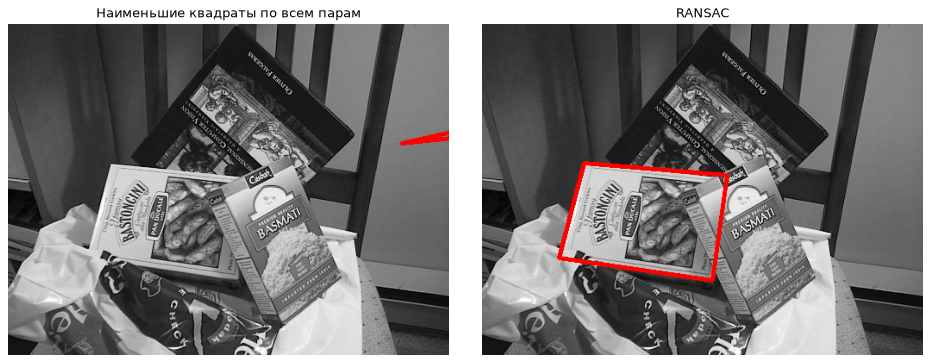

In [11]:
loose = ratio_test(knn, 0.90)
src_l = np.float32([kp_a[m.queryIdx].pt for m in loose])
dst_l = np.float32([kp_b[m.trainIdx].pt for m in loose])

H_ls, _ = dlt_homography(src_l, dst_l)                      # все пары, без отбора
H_cv_ls, _ = cv2.findHomography(src_l, dst_l, 0)
cv2.setRNGSeed(0)
H_rs, inl_l = cv2.findHomography(src_l, dst_l, cv2.RANSAC, RANSAC_THR)
inl_l = inl_l.ravel().astype(bool)

print(f"T=0.90: matches = {len(loose)}, из них inliers по RANSAC = {inl_l.sum()} ({inl_l.mean():.1%})")
for name, Hx in [("DLT по всем парам (свой)", H_ls), ("cv2.findHomography, method=0", H_cv_ls), ("RANSAC", H_rs)]:
    e = np.linalg.norm(project_points(Hx, src_l[inl_l]) - dst_l[inl_l], axis=1)
    corner_shift = np.linalg.norm(project_points(Hx, corners_a) - ref_corners, axis=1).max()
    print(f"  {name:30}: медианная ошибка на верных парах = {np.median(e):8.2f} px, сдвиг углов = {corner_shift:8.1f} px")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, (Hx, title) in zip(ax, [(H_ls, "Наименьшие квадраты по всем парам"), (H_rs, "RANSAC")]):
    v = cv2.cvtColor(img_b, cv2.COLOR_GRAY2BGR)
    cv2.polylines(v, [np.int32(np.clip(project_points(Hx, corners_a), -5000, 5000))], True, (255, 0, 0), 3)
    a.imshow(v); a.set_title(title); a.axis("off")
plt.tight_layout(); plt.show()

Наименьшие квадраты минимизируют сумму **квадратов** ошибок, поэтому одна пара с ошибкой 300 px весит как 90 000 пар с ошибкой 1 px. Решение подстраивается под выбросы, и контур коробки уезжает. RANSAC на тех же данных выбросы просто не использует.

Другие ограничения метода, которые нужно назвать на защите:

- гомография верна только для **плоского** объекта (или при чистом вращении камеры). Для объёмной сцены единой $H$ не существует;
- если точки сосредоточены в малой части объекта, $H$ хорошо описывает эту часть и плохо экстраполирует на остальное;
- RANSAC выдаёт самую «популярную» модель. Если на снимке два одинаковых объекта или повторяющийся узор, он может уверенно найти неверное преобразование.

## 6. Вывод

Цифры — из ячеек выше для пары `box.png` / `box_in_scene.png`.

- **Ratio test.** Из 604 кандидатов тест при $T=0.55$ оставляет 54 пары, при $T=0.75$ — 80, при $T=0.90$ — 174 (график шага 5). Строгий порог оставляет меньше пар, но более однозначных: при $T=0.75$ inliers составляют 75 из 80 (93.8 %), при $T=0.90$ — 86 из 174 (49.4 %). Ослабление порога добавило 94 пары, из которых верных только 11.
- **Геометрическая проверка.** Даже после ratio test 5 пар из 80 неверны (нижняя картинка шага 12), причём грубо: их ошибка от 16 px, медиана ≈ 119 px. Похожесть дескрипторов не гарантирует геометрической согласованности; RANSAC их отделяет.
- **Точность.** Ошибка репроекции по inliers: среднее 0.38 px, медиана 0.28 px, RMSE 0.49 px, максимум 1.38 px — субпиксельная.
- **Порог RANSAC.** При пороге 1 px — 70 inliers и RMSE 0.37 px; при 3 px — 75 inliers и RMSE 0.49 px. Это компромисс: строгий порог даёт более точные, но менее многочисленные inliers. Дальнейшее увеличение порога до 5 и 8 px ничего не меняет: между «хорошими» парами (ошибка до 1.4 px) и выбросами (от 16 px) пусто, и в этот промежуток никто не попадает. Сама гомография устойчива — между порогами 1 и 3 px углы коробки смещаются меньше чем на 1 px.
- **Собственные реализации.** `project_points` совпадает с `cv2.perspectiveTransform`; собственный DLT на точных данных восстанавливает $H$ с ошибкой ~1e-13, а на реальных inliers даёт тот же RMSE 0.49 px, что OpenCV.
- **Без RANSAC** (раздел 5, $T=0.9$, половина пар — выбросы) наименьшие квадраты разрушаются: медианная ошибка на заведомо верных парах 264 px у собственного DLT и 41 px у `cv2.findHomography(method=0)` (OpenCV после DLT дополнительно уточняет решение по геометрической ошибке, но выбросы остаются в данных). RANSAC на тех же парах даёт 0.32 px.
- RMSE по inliers — оптимистичная оценка: в неё по определению не входят пары с ошибкой больше порога. Честная проверка — независимые контрольные точки, не участвовавшие в оценке.
- По условию нужны две собственные фотографии; здесь использована готовая пара.

## 7. Вопросы на защиту

**1. Почему ratio test использует два ближайших дескриптора?**
Потому что проверяется не «насколько похож лучший кандидат», а «насколько он лучше остальных». Второй сосед — оценка того, как выглядит *неверное* совпадение для этой точки. Если $d_1\approx d_2$, на втором снимке есть как минимум два равноправных кандидата, и вероятность ошибки велика. Абсолютный порог на $d_1$ так не работает: типичные расстояния зависят от текстуры и освещения.

**2. Почему снижение доли inliers резко увеличивает число итераций?**
Вероятность чистой выборки равна $w^s$ — доля inliers входит в четвёртой степени. При $w=0.9$ это 0.66, при $w=0.55$ — 0.09, при $w=0.25$ — 0.004. $N$ примерно обратно пропорционально $w^s$ (при малых $w^s$: $N\approx-\ln(1-p)/w^s$), поэтому уменьшение $w$ вдвое увеличивает $N$ примерно в $2^4=16$ раз.

**3. Собственный расчёт reprojection error; зачем делить на третью компоненту.**
`project_points`: `np.c_[pts, ones]` добавляет к каждой точке единицу — переход к однородным координатам. `H @ pts_h.T` даёт три числа $(a,b,c)$. Обычные координаты — $(a/c,\ b/c)$: строка `q[:, :2] / q[:, 2:3]`. Третья компонента $c=h_{31}x+h_{32}y+h_{33}$ зависит от положения точки — это и есть перспектива: разные части плоскости масштабируются по-разному. Без деления получилось бы аффинное преобразование, при котором параллельные линии остаются параллельными. Затем `np.linalg.norm(pred − dst, axis=1)` — евклидово расстояние в пикселях для каждой пары, и `sqrt(mean(err**2))` — RMSE.